# Stage 6 — Interpretability (rebuilt)

Confirm the augmented model relies on sensible features — and check whether the new **`*_nvalid` (data-quality)** features matter, which would be a finding unique to this corrupted-data version.

In [1]:
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# new downloaded filenames (double underscores from the browser) — do NOT rename the files
TRAIN_PATH  = "Train.csv"
TEST_PATH   = "Test.csv"
SAMPLE_PATH = "SampleSubmission.csv"
NODATA = -9999            # satellite no-data sentinel in the new test set

In [2]:
# ============================================================
# Shared feature engineering — identical for train & test.
# Handles the -9999 no-data values via NaN-aware statistics.
# ============================================================
MONTHS = [f"{i:02d}" for i in range(1, 13)]
BANDS  = ["VH","VV","blue","green","nir","nira","re1","re2","re3","red","swir1","swir2"]

def load_raw(path):
    """Load a CSV and convert the -9999 no-data sentinel to NaN."""
    return pd.read_csv(path).replace(NODATA, np.nan)

def safe_ratio(a, b):
    # NaN propagates naturally; +0 denominator -> inf, cleaned later
    return (a - b) / (a + b)

def build_features(df):
    """Raw monthly bands -> engineered features.
    NaN-aware: every summary is computed over the VALID months only.
    Adds *_nvalid = how many months actually had data (a quality signal)."""
    feats = {}; idx = {}
    for m in MONTHS:
        g = df[f"green_{m}"]; n = df[f"nir_{m}"]; r = df[f"red_{m}"]; s1 = df[f"swir1_{m}"]
        idx.setdefault("NDWI",  []).append(safe_ratio(g,  n))
        idx.setdefault("MNDWI", []).append(safe_ratio(g,  s1))
        idx.setdefault("NDVI",  []).append(safe_ratio(n,  r))
        idx.setdefault("NDMI",  []).append(safe_ratio(n,  s1))
        idx.setdefault("VHmVV", []).append(df[f"VH_{m}"] - df[f"VV_{m}"])
    def summarize(monthly, name):
        a = np.column_stack([np.asarray(x, float) for x in monthly])  # rows x 12
        feats[f"{name}_mean"]  = np.nanmean(a, 1)
        feats[f"{name}_std"]   = np.nanstd(a, 1)
        feats[f"{name}_min"]   = np.nanmin(a, 1)
        feats[f"{name}_max"]   = np.nanmax(a, 1)
        feats[f"{name}_range"] = np.nanmax(a, 1) - np.nanmin(a, 1)
        feats[f"{name}_med"]   = np.nanmedian(a, 1)
        feats[f"{name}_nvalid"]= np.isfinite(a).sum(1)     # data-quality feature
    for b in BANDS: summarize([df[f"{b}_{m}"] for m in MONTHS], b)
    for k, v in idx.items(): summarize(v, k)
    return pd.DataFrame(feats, index=df.index).replace([np.inf, -np.inf], np.nan)

def corrupt(df, rate, seed=0):
    """Randomly blank band cells to mimic the test set's missingness."""
    rng = np.random.RandomState(seed); d = df.copy()
    bc = [c for c in d.columns if c not in ("ID", "label")]
    arr = d[bc].values.astype(float)
    arr[rng.rand(*arr.shape) < rate] = np.nan
    d[bc] = arr
    return d

In [3]:
import shap
from sklearn.ensemble import HistGradientBoostingClassifier

train = load_raw(TRAIN_PATH); y = train["label"].values
# fit the augmented HGB on all data
parts = [train] + [corrupt(train, r, seed=i+1) for i, r in enumerate((0.3, 0.6))]
aug = pd.concat(parts, ignore_index=True); yaug = np.concatenate([y]*len(parts))
X_aug = build_features(aug)
hgb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05,
        max_leaf_nodes=7, l2_regularization=1.0, random_state=42).fit(X_aug, yaug)
X_eval = build_features(train)
print("fitted on", X_aug.shape, "augmented rows")

fitted on (5463, 119) augmented rows


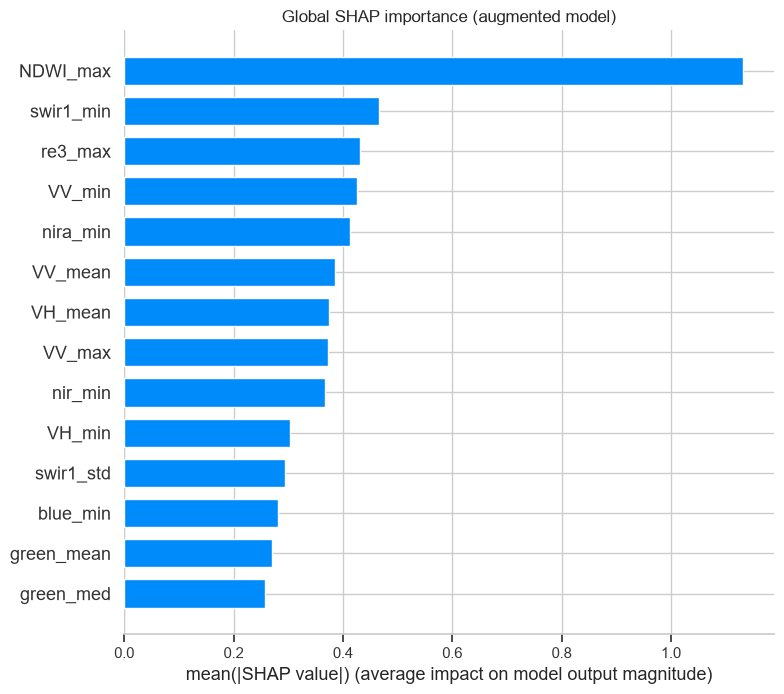

NDWI_max      1.132
swir1_min     0.466
re3_max       0.431
VV_min        0.425
nira_min      0.412
VV_mean       0.386
VH_mean       0.374
VV_max        0.374
nir_min       0.367
VH_min        0.303
swir1_std     0.294
blue_min      0.282
green_mean    0.270
green_med     0.257
dtype: float64


In [4]:
explainer = shap.TreeExplainer(hgb)
sv = explainer.shap_values(X_eval)
shap.summary_plot(sv, X_eval, plot_type="bar", max_display=14, show=False)
plt.title("Global SHAP importance (augmented model)"); plt.tight_layout(); plt.show()
imp = pd.Series(np.abs(sv).mean(0), index=X_eval.columns).sort_values(ascending=False)
print(imp.head(14).round(3))

**What to look for:**
- The water/vegetation index features (NDWI/NDVI/MNDWI summaries) should still dominate — the physics is unchanged.
- **Do any `*_nvalid` features rank highly?** If so, the model is partly keying on *how much data exists* — a genuine, dataset-specific insight worth reporting (it means data availability itself carries information about land cover here).

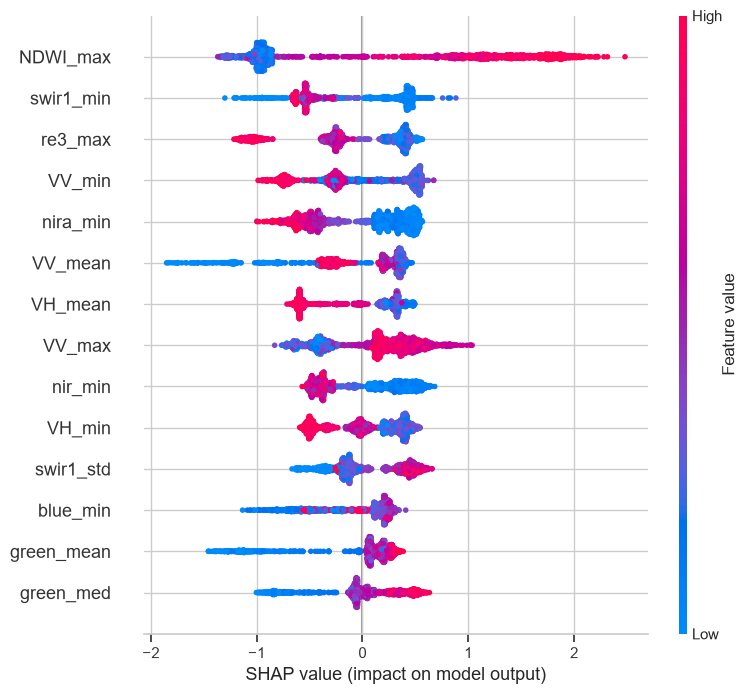

In [5]:
shap.summary_plot(sv, X_eval, max_display=14, show=False)
plt.tight_layout(); plt.show()

In [6]:
import os
os.makedirs("figures", exist_ok=True)
shap.summary_plot(sv, X_eval, plot_type="bar", max_display=14, show=False)
plt.title("Global SHAP importance"); plt.tight_layout()
plt.savefig("figures/shap_importance.png", dpi=150, bbox_inches="tight"); plt.close()
print("saved figures/shap_importance.png")

saved figures/shap_importance.png


## Stage 6 takeaways
- Index features remain the backbone — model is right for the right (physical) reasons.
- Watch the **`*_nvalid`** features: their importance is the fingerprint of this corrupted-data task.
- Figure saved for the Model Transparency writeup.

**Next (Stage 7):** final model, submission, validation, trustworthiness sections.